# Video keypoint autoencoder: anomaly detection and posture indicators

VTT-ConIoT video keypoints (CC BY 4.0, Zenodo 4683703). Features are the x/y coordinates of 17 COCO points, hip-centred and divided by median torso length, then standardized using normal training windows only.

Normal tasks: 13, 14, 15. Selected comparison tasks: 7, 8, 11, 12. Train workers 1â€“9; validation workers 10â€“11; test workers 12â€“13. Workers do not overlap. â€œAnomalousâ€ means different from those selected normal tasks, not fatigue, danger, stress, or validated worker strain. Joint angles are approximate 2D posture indicators.

COCO point order: nose; left/right eyes; left/right ears; left/right shoulders; left/right elbows; left/right wrists; left/right hips; left/right knees; left/right ankles. Compare pmin=0.02 (default) and pmin=0.1. Each run refits preprocessing and a separate scaler using only its normal training windows.

In [1]:
import copy, ctypes, json, os, random, sys, time
from pathlib import Path
if os.name == "nt":
    ctypes.WinDLL(os.path.join(os.environ["SystemRoot"], "System32", "msvcp140.dll"))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.utils.data import DataLoader, TensorDataset
from sklearn.decomposition import PCA
from sklearn.metrics import roc_auc_score, roc_curve, precision_score, recall_score
HERE = Path.cwd()
ROOT = next(p for p in [HERE, *HERE.parents] if (p / "data").exists())
DATA_DIR = ROOT / "data" / "VTT_ConIot_Dataset" / "VTT-ConIoT-Video-Keypoints"
REPORT_DIR, MODEL_DIR = ROOT / "reports" / "keypoint", ROOT / "models" / "keypoint"
REPORT_DIR.mkdir(parents=True, exist_ok=True); MODEL_DIR.mkdir(parents=True, exist_ok=True)
sys.path.insert(0, str(HERE))
import keypoint_utils as ku
BATCH_SIZE, EPOCHS, PATIENCE, SEED = 64, 40, 6, 42
THRESHOLD_PCT, DEFAULT_PMIN = 90, 0.02
PMIN_RUNS = (0.02, 0.1)
W, F = ku.WINDOW, ku.N_FEAT
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Root:", ROOT, "| data:", DATA_DIR, "| device:", device, "| torch", torch.__version__)

Root: d:\Work\IAAC\Hackaton_Group3_AIMethods | data: d:\Work\IAAC\Hackaton_Group3_AIMethods\data\VTT_ConIot_Dataset\VTT-ConIoT-Video-Keypoints | device: cpu | torch 2.15.0+cpu


## Data layout and preprocessing checks

Expected CSV names are Subject_NN_Task_X...csv and columns are frame_number, timestamp, x/y/prob for points 0â€“16, and detection_score. Training and validation use STRIDE_TRAIN; test and inference are non-overlapping. Shared helper functions keep confidence filtering, interpolation, centering, torso normalization, and clipping consistent.

In [2]:
files = ku.find_files(DATA_DIR)
assert files, f"No keypoint CSVs found under {DATA_DIR}"
header = pd.read_csv(files[0][2], nrows=0).columns.tolist()
assert not [name for name in ku.KEYPOINT_COLUMNS if name not in header]
assert len(ku.COCO_POINT_NAMES) == 17 and W == 48 and F == 34
print("CSV recordings:", len(files), "| sample:", files[0][2].name)
print("Expected x/y/prob columns present; COCO indices:", ku.COCO_POINT_NAMES)
print("Shape:", (W, F), "| train/validation stride:", ku.STRIDE_TRAIN, "| test/inference stride:", W)

CSV recordings: 194 | sample: Subject_01_Task_1.m2ts_keyPoints.csv
Expected x/y/prob columns present; COCO indices: ['nose', 'left_eye', 'right_eye', 'left_ear', 'right_ear', 'left_shoulder', 'right_shoulder', 'left_elbow', 'right_elbow', 'left_wrist', 'right_wrist', 'left_hip', 'right_hip', 'left_knee', 'right_knee', 'left_ankle', 'right_ankle']
Shape: (48, 34) | train/validation stride: 24 | test/inference stride: 48


## Model setups

The three neural networks share a training loop. PCA and pose deviation are reference methods only and are not considered for selecting a neural network.

In [3]:
class Dense(nn.Module):
    def __init__(self, latent=16):
        super().__init__()
        self.enc=nn.Sequential(nn.Flatten(),nn.Linear(W*F,128),nn.ReLU(),nn.Linear(128,latent))
        self.dec=nn.Sequential(nn.Linear(latent,128),nn.ReLU(),nn.Linear(128,W*F),nn.Unflatten(1,(W,F)))
    def encode(self,x): return self.enc(x)
    def decode(self,z): return self.dec(z)
    def forward(self,x): return self.decode(self.encode(x))

class Conv(nn.Module):
    def __init__(self,latent=16):
        super().__init__()
        self.enc=nn.Sequential(nn.Conv1d(F,32,5,2,2),nn.ReLU(),nn.Conv1d(32,64,5,2,2),nn.ReLU(),
            nn.Conv1d(64,64,5,2,2),nn.ReLU(),nn.Flatten(),nn.Linear(64*6,latent))
        self.dec=nn.Sequential(nn.Linear(latent,64*6),nn.ReLU(),nn.Unflatten(1,(64,6)),
            nn.ConvTranspose1d(64,64,4,2,1),nn.ReLU(),nn.ConvTranspose1d(64,32,4,2,1),nn.ReLU(),
            nn.ConvTranspose1d(32,F,4,2,1))
    def encode(self,x): return self.enc(x.transpose(1,2))
    def decode(self,z): return self.dec(z).transpose(1,2)
    def forward(self,x): return self.decode(self.encode(x))

SETUPS={"A Dense, latent 16":lambda:Dense(16),"B Conv1d, latent 16":lambda:Conv(16),
        "C Conv1d, latent 8":lambda:Conv(8)}
assert all(build()(torch.zeros(2,W,F)).shape==(2,W,F) for build in SETUPS.values())
print("All setup outputs have shape:",(W,F))

All setup outputs have shape: (48, 34)


In [4]:
def loader(a,shuffle=False):
    return DataLoader(TensorDataset(torch.from_numpy(a)),batch_size=BATCH_SIZE,shuffle=shuffle)

def errors(model,x):
    model.eval(); out=[]
    with torch.no_grad():
        for (b,) in loader(x):
            b=b.to(device); out.append((model(b)-b).square().mean((1,2)).cpu().numpy())
    return np.concatenate(out)

def fit(name,build,train_x,val_x):
    random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
    model=build().to(device); opt=torch.optim.Adam(model.parameters(),lr=1e-3)
    best,best_state,stale=float("inf"),None,0; hist=[]; t0=time.perf_counter()
    for epoch in range(1,EPOCHS+1):
        model.train(); total=0.0
        for (b,) in loader(train_x,True):
            b=b.to(device); opt.zero_grad(set_to_none=True)
            loss=(model(b)-b).square().mean(); loss.backward(); opt.step(); total+=loss.item()*len(b)
        tr=total/len(train_x); va=float(errors(model,val_x).mean()); hist.append((epoch,tr,va))
        print(f"{name} | epoch {epoch:02d} | train {tr:.4f} | val {va:.4f}")
        if va<best: best,best_state,stale=va,copy.deepcopy(model.state_dict()),0
        else:
            stale+=1
            if stale>=PATIENCE: print("early stopping"); break
    model.load_state_dict(best_state)
    return model,pd.DataFrame(hist,columns=["epoch","train","val"]),sum(p.numel() for p in model.parameters()),time.perf_counter()-t0

def threshold_metrics(val_err,test_err,labels):
    cut=float(np.percentile(val_err,90)); pred=(test_err>cut).astype(int)
    return cut,precision_score(labels,pred,zero_division=0),recall_score(labels,pred,zero_division=0)

## Train, select on validation, then evaluate test

Each pmin run rebuilds windows and its scaler independently. Normal validation MSE selects the best neural network before test metrics are calculated. Test results are only final held-out evaluation/comparison.

In [5]:
def run(pmin):
    d=ku.build_splits(DATA_DIR,pmin=pmin)
    tx,vx,ex=d["train_x"],d["val_x"],d["test_x"]
    tm,vm,em=d["train_meta"],d["val_meta"],d["test_meta"]
    labels=d["test_label"]
    assert set(tm[:,0]).isdisjoint(vm[:,0]) and set(tm[:,0]).isdisjoint(em[:,0]) and set(vm[:,0]).isdisjoint(em[:,0])
    assert set(np.unique(tm[:,0])).issubset(ku.TRAIN_USERS) and set(np.unique(vm[:,0])).issubset(ku.VAL_USERS)
    assert set(np.unique(em[:,0])).issubset(ku.TEST_USERS)
    assert set(np.unique(tm[:,1])).issubset(ku.NORMAL) and set(np.unique(vm[:,1])).issubset(ku.NORMAL)
    assert set(np.unique(em[:,1])).issubset(set(ku.NORMAL+ku.ANOMALOUS))
    assert tx.shape[1:]==vx.shape[1:]==ex.shape[1:]==(W,F)
    print(f"pmin={pmin}: train={len(tx)} validation={len(vx)} test={len(ex)} "
          f"(normal={int(sum(labels==0))}, comparison={int(sum(labels==1))})")
    print("Scaler fitted on normal training windows for this pmin run.")
    models={n:fit(n,b,tx,vx) for n,b in SETUPS.items()}
    val_mse={n:float(errors(m,vx).mean()) for n,(m,_,_,_) in models.items()}
    best=min(SETUPS,key=lambda n:val_mse[n])
    print(f"Selected by normal validation MSE only: {best} ({val_mse[best]:.6f})")
    rows=[]; scores={}; cuts={}
    # Test metrics are final evaluation/comparison after validation-only selection.
    for n,(m,h,params,seconds) in models.items():
        ve,te=errors(m,vx),errors(m,ex); cut,pr,rc=threshold_metrics(ve,te,labels)
        scores[n],cuts[n]=te,cut
        rows.append({"Setup":n,"Parameters":params,"Training time (s)":round(seconds,1),
          "Epochs run":len(h),"Val MSE (normal)":round(val_mse[n],4),
          "Test MSE (all)":round(float(te.mean()),4),"Test ROC AUC":round(roc_auc_score(labels,te),3),
          "Test precision":round(pr,3),"Test recall":round(rc,3),"Threshold":round(cut,4)})
    flat=lambda a:a.reshape(len(a),-1)
    pca=PCA(8,random_state=SEED).fit(flat(tx))
    pca_err=lambda a:((flat(a)-pca.inverse_transform(pca.transform(flat(a))))**2).mean(1)
    pv,pt=pca_err(vx),pca_err(ex); cut,pr,rc=threshold_metrics(pv,pt,labels)
    rows.append({"Setup":"Reference: PCA, 8 components","Parameters":int(pca.components_.size),
      "Val MSE (normal)":round(float(pv.mean()),4),"Test MSE (all)":round(float(pt.mean()),4),
      "Test ROC AUC":round(roc_auc_score(labels,pt),3),"Test precision":round(pr,3),
      "Test recall":round(rc,3),"Threshold":round(cut,4)})
    dev=lambda a:(a**2).mean(axis=(1,2)); dv,dt=dev(vx),dev(ex)
    cut,pr,rc=threshold_metrics(dv,dt,labels)
    rows.append({"Setup":"Reference: pose deviation","Test ROC AUC":round(roc_auc_score(labels,dt),3),
      "Test precision":round(pr,3),"Test recall":round(rc,3),"Threshold":round(cut,4)})
    return {"pmin":pmin,"data":d,"models":models,"val_mse":val_mse,"best":best,
      "best_model":models[best][0],"scores":scores,"cuts":cuts,"results":pd.DataFrame(rows),
      "pca_test":pt,"pose_test":dt}
experiments={p:run(p) for p in PMIN_RUNS}

pmin=0.02: train=1473 validation=225 test=396 (normal=148, comparison=248)
Scaler fitted on normal training windows for this pmin run.
A Dense, latent 16 | epoch 01 | train 0.7459 | val 0.4557
A Dense, latent 16 | epoch 02 | train 0.3648 | val 0.3918
A Dense, latent 16 | epoch 03 | train 0.2901 | val 0.3715
A Dense, latent 16 | epoch 04 | train 0.2611 | val 0.3570
A Dense, latent 16 | epoch 05 | train 0.2356 | val 0.3323
A Dense, latent 16 | epoch 06 | train 0.2124 | val 0.3117
A Dense, latent 16 | epoch 07 | train 0.1982 | val 0.2984
A Dense, latent 16 | epoch 08 | train 0.1911 | val 0.2872
A Dense, latent 16 | epoch 09 | train 0.1810 | val 0.2784
A Dense, latent 16 | epoch 10 | train 0.1740 | val 0.2698
A Dense, latent 16 | epoch 11 | train 0.1688 | val 0.2648
A Dense, latent 16 | epoch 12 | train 0.1678 | val 0.2617
A Dense, latent 16 | epoch 13 | train 0.1620 | val 0.2560
A Dense, latent 16 | epoch 14 | train 0.1620 | val 0.2508
A Dense, latent 16 | epoch 15 | train 0.1513 | val 0.

c:\Users\nandi\AppData\Local\Programs\Python\Python312\Lib\site-packages\numpy\lib\_nanfunctions_impl.py:1215: RuntimeWarning: All-NaN slice encountered
  return fnb._ureduce(a, func=_nanmedian, keepdims=keepdims,
c:\Users\nandi\AppData\Local\Programs\Python\Python312\Lib\site-packages\numpy\lib\_nanfunctions_impl.py:1215: RuntimeWarning: All-NaN slice encountered
  return fnb._ureduce(a, func=_nanmedian, keepdims=keepdims,
c:\Users\nandi\AppData\Local\Programs\Python\Python312\Lib\site-packages\numpy\lib\_nanfunctions_impl.py:1215: RuntimeWarning: All-NaN slice encountered
  return fnb._ureduce(a, func=_nanmedian, keepdims=keepdims,


pmin=0.1: train=546 validation=113 test=181 (normal=63, comparison=118)
Scaler fitted on normal training windows for this pmin run.
A Dense, latent 16 | epoch 01 | train 0.9585 | val 0.6074
A Dense, latent 16 | epoch 02 | train 0.6705 | val 0.3503
A Dense, latent 16 | epoch 03 | train 0.4490 | val 0.2696
A Dense, latent 16 | epoch 04 | train 0.3743 | val 0.2488
A Dense, latent 16 | epoch 05 | train 0.3363 | val 0.2366
A Dense, latent 16 | epoch 06 | train 0.3095 | val 0.2258
A Dense, latent 16 | epoch 07 | train 0.2844 | val 0.2152
A Dense, latent 16 | epoch 08 | train 0.2633 | val 0.2037
A Dense, latent 16 | epoch 09 | train 0.2414 | val 0.1962
A Dense, latent 16 | epoch 10 | train 0.2259 | val 0.1867
A Dense, latent 16 | epoch 11 | train 0.2141 | val 0.1816
A Dense, latent 16 | epoch 12 | train 0.2047 | val 0.1752
A Dense, latent 16 | epoch 13 | train 0.1951 | val 0.1686
A Dense, latent 16 | epoch 14 | train 0.1860 | val 0.1630
A Dense, latent 16 | epoch 15 | train 0.1787 | val 0.158

In [6]:
# Check inference preprocessing against standardized non-overlapping test windows.
d0=experiments[DEFAULT_PMIN]["data"]
user,task,feats,valid=d0["records"][0]
clip_path=next(path for u,t,path in ku.find_files(DATA_DIR) if u==user and t==task)
x,y,prob=ku.read_keypoints(clip_path)
inference_x=ku.preprocess_for_model(x,y,prob,d0["mean"],d0["scale"],pmin=DEFAULT_PMIN)
raw_test,_=ku.make_windows([(user,task,feats,valid)],[user],[task],ku.WINDOW)
expected_x=((raw_test-d0["mean"])/d0["scale"]).astype(np.float32)
assert np.allclose(inference_x,expected_x,atol=1e-6)
print("Inference preprocessing matches standardized non-overlapping test windows:",inference_x.shape)

Inference preprocessing matches standardized non-overlapping test windows: (31, 48, 34)


In [7]:
default=experiments[DEFAULT_PMIN]
default["results"].to_csv(REPORT_DIR/"setups_table.csv",index=False)
default["results"]

,Setup,Parameters,Training time (s),Epochs run,Val MSE (normal),Test MSE (all),Test ROC AUC,Test precision,Test recall,Threshold
0,"A Dense, latent 16",423792.0,1.9,40.0,0.2079,0.4320,0.784,0.846,0.419,0.6588
1,"B Conv1d, latent 16",78066.0,5.8,40.0,0.3095,0.7845,0.807,0.901,0.585,1.1723
2,"C Conv1d, latent 8",71914.0,5.4,40.0,0.3040,0.8689,0.814,0.913,0.637,1.2108
3,"Reference: PCA, 8 components",13056.0,NaN,NaN,0.2670,0.4504,0.766,0.238,0.020,1.0259
4,Reference: pose deviation,NaN,NaN,NaN,NaN,NaN,0.843,0.891,0.657,1.8396


In [8]:
sensitivity=[]
for p,run_ in experiments.items():
    d=run_["data"]; name=run_["best"]; te=run_["scores"][name]
    cut,pr,rc=threshold_metrics(errors(run_["best_model"],d["val_x"]),te,d["test_label"])
    sensitivity.append({"pmin":p,"Selected model (validation MSE)":name,
      "Normal validation MSE":round(run_["val_mse"][name],4),"Train windows":len(d["train_x"]),
      "Validation windows":len(d["val_x"]),"Test windows":len(d["test_x"]),
      "Test normal":int(sum(d["test_label"]==0)),"Test comparison":int(sum(d["test_label"]==1)),
      "Test MSE (all)":round(float(te.mean()),4),"Test ROC AUC":round(roc_auc_score(d["test_label"],te),3),
      "Test precision":round(pr,3),"Test recall":round(rc,3),"Threshold":round(cut,4)})
sensitivity=pd.DataFrame(sensitivity)
sensitivity.to_csv(REPORT_DIR/"pmin_sensitivity.csv",index=False)
sensitivity

,pmin,Selected model (validation MSE),Normal validation MSE,Train windows,Validation windows,Test windows,Test normal,Test comparison,Test MSE (all),Test ROC AUC,Test precision,Test recall,Threshold
0,0.02,"A Dense, latent 16",0.2079,1473,225,396,148,248,0.432,0.784,0.846,0.419,0.6588
1,0.10,"A Dense, latent 16",0.1150,546,113,181,63,118,0.496,0.858,0.923,0.610,0.2158


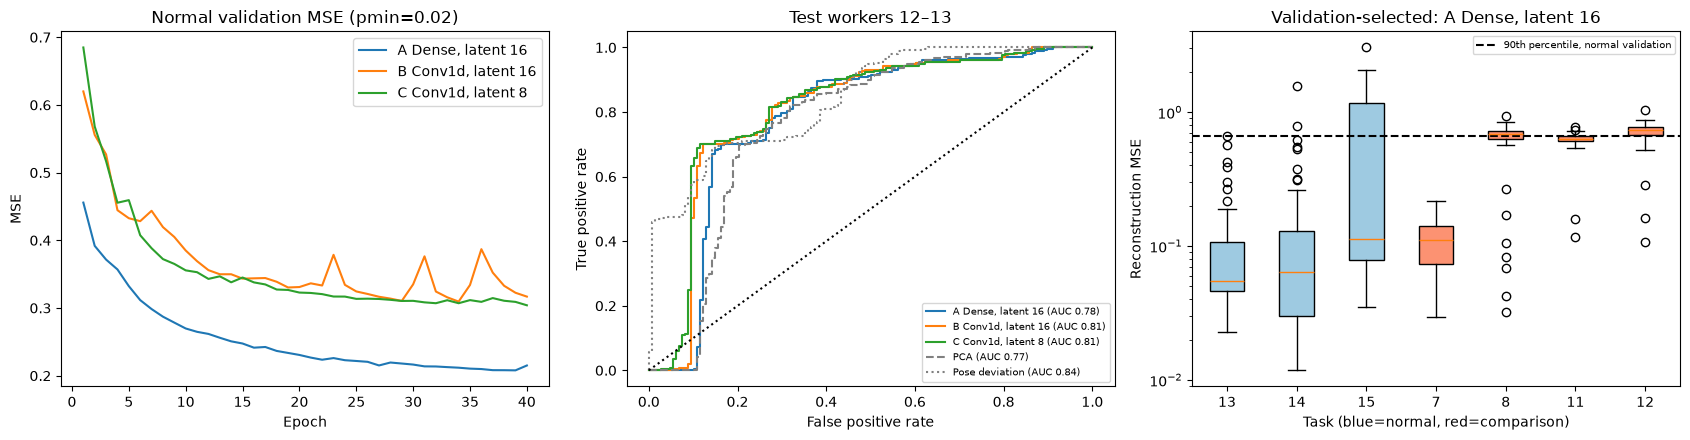

In [9]:
fig,ax=plt.subplots(1,3,figsize=(17,4.5))
for name,(_,hist,_,_) in default["models"].items():
    ax[0].plot(hist.epoch,hist.val,label=name)
ax[0].set(title="Normal validation MSE (pmin=0.02)",xlabel="Epoch",ylabel="MSE"); ax[0].legend()
labels=default["data"]["test_label"]
for name,e in default["scores"].items():
    fpr,tpr,_=roc_curve(labels,e); ax[1].plot(fpr,tpr,label=f"{name} (AUC {roc_auc_score(labels,e):.2f})")
for label,e,style in [("PCA",default["pca_test"],"--"),("Pose deviation",default["pose_test"],":")]:
    fpr,tpr,_=roc_curve(labels,e); ax[1].plot(fpr,tpr,style,color="grey",label=f"{label} (AUC {roc_auc_score(labels,e):.2f})")
ax[1].plot([0,1],[0,1],":",color="black")
ax[1].set(title="Test workers 12–13",xlabel="False positive rate",ylabel="True positive rate"); ax[1].legend(fontsize=7)
d=default["data"]; name=default["best"]; tasks=ku.NORMAL+ku.ANOMALOUS
groups=[default["scores"][name][d["test_meta"][:,1]==t] for t in tasks]
bp=ax[2].boxplot(groups,tick_labels=[str(t) for t in tasks],patch_artist=True)
for patch,t in zip(bp["boxes"],tasks): patch.set_facecolor("#9ecae1" if t in ku.NORMAL else "#fc9272")
ax[2].axhline(default["cuts"][name],color="black",linestyle="--",label="90th percentile, normal validation")
ax[2].set(title=f"Validation-selected: {name}",xlabel="Task (blue=normal, red=comparison)",ylabel="Reconstruction MSE")
ax[2].set_yscale("log"); ax[2].legend(fontsize=7); fig.tight_layout()
fig.savefig(REPORT_DIR/"keypoint_anomaly_figure.png",dpi=160)

## Approximate 2D posture indicators

These joint angles are approximate 2D posture indicators derived from video keypoints. They are not fatigue, danger, stress, or validated worker-strain measurements. Selected comparison tasks are simply movements different from tasks 13â€“15.

,trunk_lean,knee_bend,arm_elevation
task,,,
1,3.0,7.0,61.0
2,3.0,12.0,44.0
3,6.0,15.0,86.0
4,9.0,10.0,33.0
5,5.0,16.0,29.0
6,3.0,5.0,23.0
7,3.0,13.0,26.0
8,15.0,19.0,141.0
9,6.0,11.0,139.0


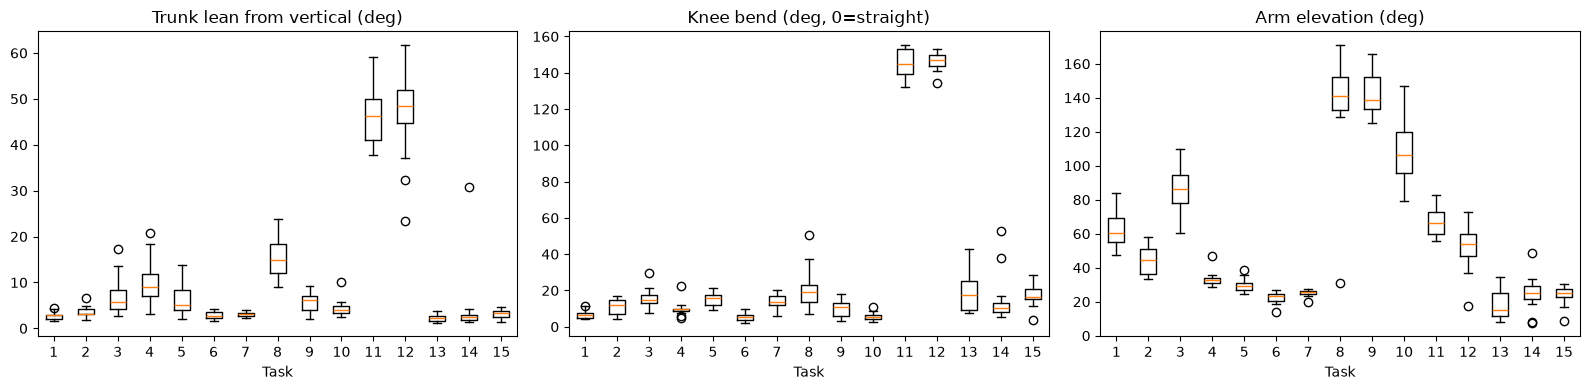

In [10]:
rows=[]
angle_records=ku.load_records(DATA_DIR,list(range(1,16)),pmin=DEFAULT_PMIN)
for user,task,feats,valid in angle_records:
    a=ku.joint_angles(feats)
    rows.append({"task":task,"user":user,"trunk_lean":np.median(a["trunk_lean"]),
      "knee_bend":180-np.median(np.minimum(a["knee_left"],a["knee_right"])),
      "arm_elevation":np.median(np.maximum(a["shoulder_left"],a["shoulder_right"]))})
angles=pd.DataFrame(rows)
summary=angles.groupby("task")[["trunk_lean","knee_bend","arm_elevation"]].median().round(0)
summary.to_csv(REPORT_DIR/"posture_angles_by_task.csv")
fig,ax=plt.subplots(1,3,figsize=(16,4))
for axis,col,title in zip(ax,["trunk_lean","knee_bend","arm_elevation"],
  ["Trunk lean from vertical (deg)","Knee bend (deg, 0=straight)","Arm elevation (deg)"]):
    axis.boxplot([angles[angles.task==t][col].values for t in range(1,16)],tick_labels=[str(t) for t in range(1,16)])
    axis.set(title=title,xlabel="Task")
fig.tight_layout(); fig.savefig(REPORT_DIR/"posture_angles_figure.png",dpi=160)
summary

## Export the default model and verify ONNX

The exported model, scaler, and config all use pmin=0.02. The config records inference preprocessing. The shared helper runs inference windows without overlap and applies the same cleaning/normalization/scaler used in training.

In [11]:
best_model=default["best_model"].cpu().eval()
class WithEmbedding(nn.Module):
    def __init__(self,model): super().__init__(); self.model=model
    def forward(self,x):
        z=self.model.encode(x); return z,self.model.decode(z)
example=torch.zeros(2,W,F,dtype=torch.float32)
onnx_path=MODEL_DIR/"model.onnx"
torch.onnx.export(WithEmbedding(best_model).eval(),(example,),str(onnx_path),
  input_names=["keypoint_window"],output_names=["embedding","reconstruction"],
  dynamic_shapes={"x":{0:torch.export.Dim("batch")}},external_data=False)
np.savez(MODEL_DIR/"scaler.npz",mean=default["data"]["mean"],scale=default["data"]["scale"])
config={"model":default["best"],"input":"keypoint_window (batch, 48, 34)","window_frames":W,"fps":ku.FPS,
 "n_features":F,"normal_tasks":ku.NORMAL,"comparison_tasks":ku.ANOMALOUS,
 "threshold_mse":default["cuts"][default["best"]],"threshold_rule":"90th percentile of normal validation error",
 "pmin":DEFAULT_PMIN,"preprocessing":{"pmin":DEFAULT_PMIN,"max_gap_frames":ku.MAX_GAP,"clip":ku.CLIP,
 "max_missing":ku.MAX_MISSING,"scale_floor":ku.SCALE_FLOOR,
 "normalise":"x,y minus hip centre, divided by median torso length","inference_window_stride":ku.WINDOW},
 "train_users":ku.TRAIN_USERS,"validation_users":ku.VAL_USERS,"test_users":ku.TEST_USERS,
 "seed":SEED,"torch_version":str(torch.__version__)}
(MODEL_DIR/"config.json").write_text(json.dumps(config,indent=2),encoding="utf-8")
import onnxruntime as ort
session=ort.InferenceSession(str(onnx_path),providers=["CPUExecutionProvider"])
emb,rec=session.run(["embedding","reconstruction"],{"keypoint_window":example.numpy()})
with torch.no_grad():
    z=best_model.encode(example); reconstructed=best_model.decode(z)
embedding_match=np.allclose(z.detach().cpu().numpy(),emb,atol=1e-5)
reconstruction_match=np.allclose(reconstructed.detach().cpu().numpy(),rec,atol=1e-5)
print("ONNX matches PyTorch (embedding, reconstruction):",embedding_match,reconstruction_match)
assert embedding_match and reconstruction_match

[torch.onnx] Obtain model graph for `WithEmbedding([...]` with `torch.export.export(..., strict=False)`...
[torch.onnx] Obtain model graph for `WithEmbedding([...]` with `torch.export.export(..., strict=False)`... ✅
[torch.onnx] Run decompositions...
[torch.onnx] Run decompositions... ✅
[torch.onnx] Translate the graph into ONNX...
[torch.onnx] Translate the graph into ONNX... ✅
[torch.onnx] Optimize the ONNX graph...
[torch.onnx] Optimize the ONNX graph... ✅
ONNX matches PyTorch (embedding, reconstruction): True True
